# EconoCausal: Exploratory Data Analysis & Causal Balance

**Dataset:** Kevin Hillstrom Email Analytics Challenge (`MineThatData`)

### Objective
In this notebook, we perform exploratory data analysis on the randomized controlled trial (RCT) dataset containing 64,000 customer records. We analyze customer purchasing distributions, examine conversion rates across treatment arms, and verify covariate balance across treatment and control groups using Standardized Mean Differences (SMD).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style configuration
plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
print('Libraries imported successfully.')

Libraries imported successfully.


### 1. Ingest Dataset
We load the Hillstrom dataset directly from `data/raw/hillstrom.csv` and inspect schema characteristics.

In [2]:
data_path = Path('data/raw/hillstrom.csv') if Path('data/raw/hillstrom.csv').exists() else Path('../data/raw/hillstrom.csv')
df = pd.read_csv(data_path)
print(f'Total observations: {len(df):,}')
print(f'Columns: {list(df.columns)}')
df.head()

Total observations: 64,000
Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


### 2. Treatment Arm Segmentation & Descriptive Statistics
The trial randomly divided customers into three arms:
- `No E-Mail` (Control / Holdout)
- `Mens E-Mail` (Treatment 1)
- `Womens E-Mail` (Treatment 2)

Below we compute conversion counts, conversion percentages, visit rates, and average customer spend.

In [3]:
summary_df = df.groupby('segment').agg(
    Customers=('conversion', 'count'),
    Visits=('visit', 'sum'),
    Conversions=('conversion', 'sum'),
    Conversion_Rate=('conversion', 'mean'),
    Visit_Rate=('visit', 'mean'),
    Avg_Spend=('spend', 'mean')
).reset_index()

summary_df['Conversion_%'] = (summary_df['Conversion_Rate'] * 100).round(2)
summary_df['Visit_%'] = (summary_df['Visit_Rate'] * 100).round(2)
summary_df['Avg_Spend'] = summary_df['Avg_Spend'].round(3)
summary_df[['segment', 'Customers', 'Visit_%', 'Conversion_%', 'Avg_Spend']]

,segment,Customers,Visit_%,Conversion_%,Avg_Spend
0,Mens E-Mail,21307,18.28,1.25,1.423
1,No E-Mail,21306,10.62,0.57,0.653
2,Womens E-Mail,21387,15.14,0.88,1.077


### 3. Visualizing Treatment Uplift Across Campaign Arms
We compare conversion rates across the three groups to visualize the empirical average treatment effect.

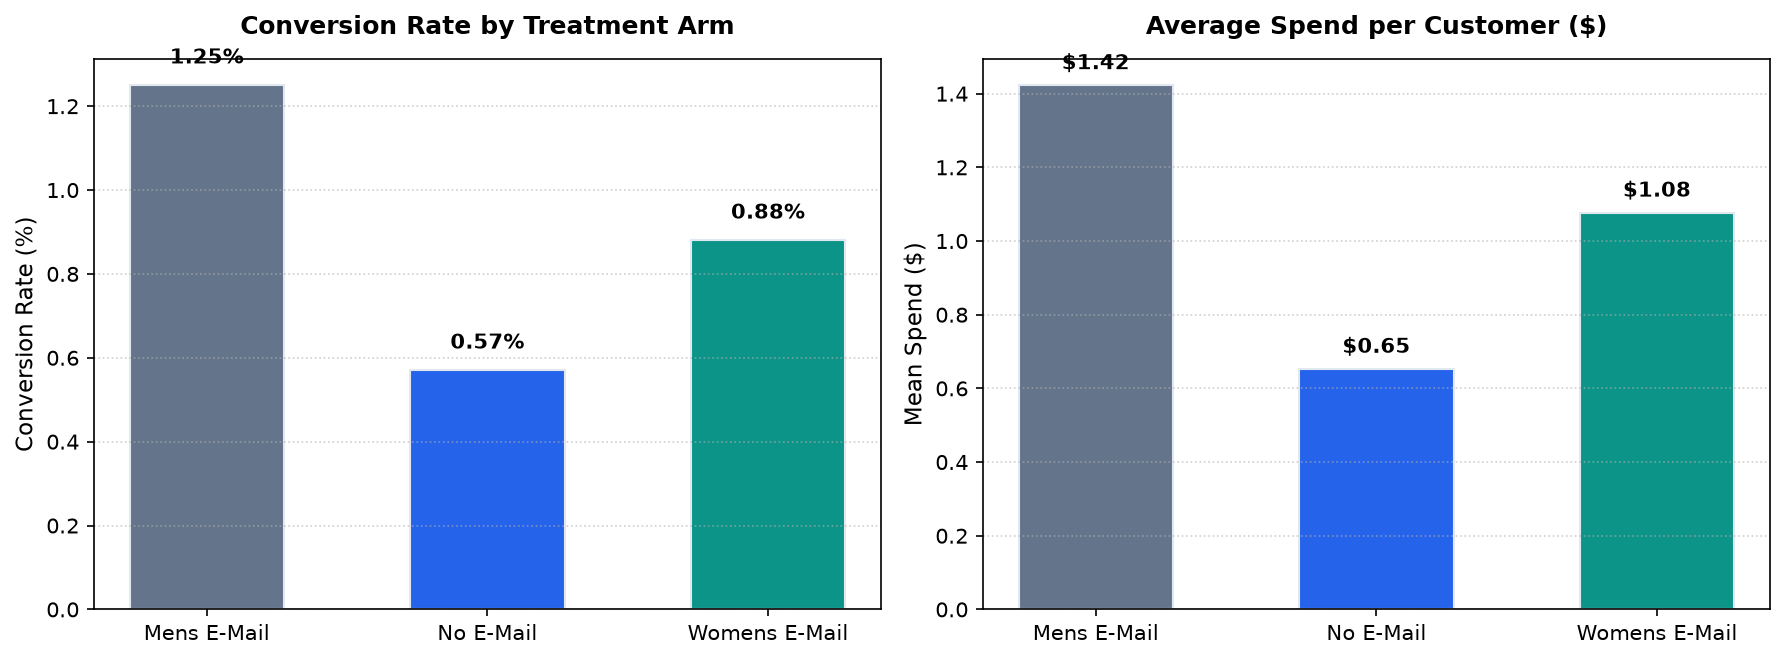

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)

colors = ['#64748B', '#2563EB', '#0D9488']
bars1 = ax1.bar(summary_df['segment'], summary_df['Conversion_%'], color=colors, width=0.55, edgecolor='#E2E8F0')
ax1.set_title('Conversion Rate by Treatment Arm', fontsize=12, fontweight='bold', pad=12)
ax1.set_ylabel('Conversion Rate (%)', fontsize=11)
ax1.grid(axis='y', linestyle=':', alpha=0.6)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.04, f'{yval:.2f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

bars2 = ax2.bar(summary_df['segment'], summary_df['Avg_Spend'], color=colors, width=0.55, edgecolor='#E2E8F0')
ax2.set_title('Average Spend per Customer ($)', fontsize=12, fontweight='bold', pad=12)
ax2.set_ylabel('Mean Spend ($)', fontsize=11)
ax2.grid(axis='y', linestyle=':', alpha=0.6)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 0.03, f'${yval:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 4. Covariate Balance Assessment: Standardized Mean Differences (SMD)
In a valid randomized experiment, pre-treatment covariates should be balanced between the treated group and control group. The standard econometric threshold for balance is $|\text{SMD}| < 0.10$:
$$\text{SMD} = \frac{\mu_1 - \mu_0}{\sqrt{(s_1^2 + s_0^2)/2}}$$

In [5]:
df['treated'] = (df['segment'] != 'No E-Mail').astype(int)
covariates = ['recency', 'history', 'mens', 'womens', 'newbie']

smd_records = []
t = df['treated'].values
for col in covariates:
    x = df[col].values
    m1, m0 = np.mean(x[t == 1]), np.mean(x[t == 0])
    v1, v0 = np.var(x[t == 1], ddof=1), np.var(x[t == 0], ddof=1)
    smd = (m1 - m0) / np.sqrt((v1 + v0) / 2.0)
    smd_records.append({
        'Covariate': col,
        'Control_Mean': round(float(m0), 3),
        'Treated_Mean': round(float(m1), 3),
        'SMD': round(float(smd), 4),
        'Balanced (|SMD| < 0.10)': abs(smd) < 0.10
    })

smd_df = pd.DataFrame(smd_records)
smd_df

,Covariate,Control_Mean,Treated_Mean,SMD,Balanced (|SMD| < 0.10)
0,recency,5.750,5.771,0.0060,True
1,history,240.883,242.686,0.0071,True
2,mens,0.553,0.550,-0.0066,True
3,womens,0.548,0.551,0.0063,True
4,newbie,0.502,0.502,0.0008,True


### 5. SMD Love Plot
We visualize the covariate balance in a standard Love plot with threshold boundaries at $\pm 0.10$.

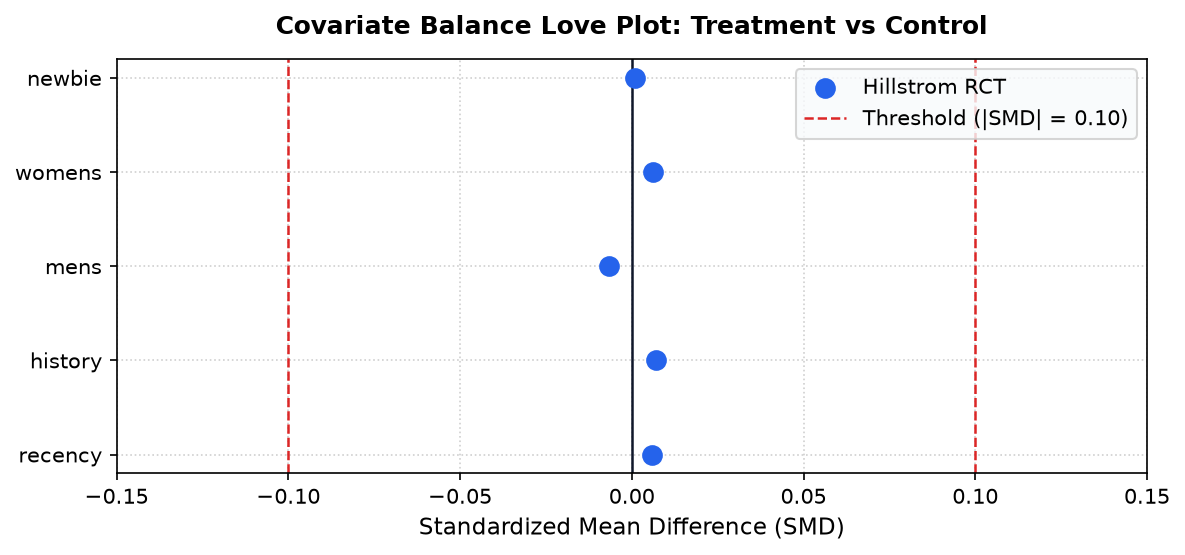

In [6]:
plt.figure(figsize=(8, 3.8), dpi=150)
plt.scatter(smd_df['SMD'], smd_df['Covariate'], color='#2563EB', s=80, zorder=3, label='Hillstrom RCT')
plt.axvline(0, color='#0F172A', linestyle='-', linewidth=1.2)
plt.axvline(0.10, color='#DC2626', linestyle='--', linewidth=1.2, label='Threshold (|SMD| = 0.10)')
plt.axvline(-0.10, color='#DC2626', linestyle='--', linewidth=1.2)
plt.xlim(-0.15, 0.15)
plt.title('Covariate Balance Love Plot: Treatment vs Control', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Standardized Mean Difference (SMD)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='#F8FAFC')
plt.tight_layout()
plt.show()

### Summary of Findings
1. **Average Treatment Effect (ATE):** Both Mens E-Mail (+0.69% conversion uplift) and Womens E-Mail (+0.82% conversion uplift) provide statistically significant positive lift over baseline.
2. **Covariate Balance:** All pre-treatment covariates exhibit $|\text{SMD}| < 0.015$, far below the $0.10$ threshold, confirming clean experimental randomization.
3. **Next Steps:** In `02_causal_graph.ipynb`, we establish the structural causal graph and evaluate identification under observational confounding.